# EV Battery: 10-Cycle-Ahead SOH Forecasting

## Objective

Forecast the **State of Health (SOH) exactly 10 cycles ahead** and identify whether the battery is undergoing **accelerated degradation**.

## Models Compared

1. **Random Forest Regressor** — Basic Machine Learning
2. **XGBoost Regressor** — Gradient Boosting Machine Learning
3. **Neural Network (MLP)** — Deep Learning
4. **ARIMA**- Temporal Model

## Target

The prediction target is:

**SOH at cycle `t + 10`**

The model uses information available at cycle `t` to forecast the battery's SOH **10 cycles into the future**.

## Outputs

For each prediction, the system produces:

- **Predicted SOH (`t + 10`)**
- **Expected SOH Degradation**
- **Recent Degradation Rate**
- **Long-Term Degradation Rate**
- **Acceleration Ratio**
- **Continuous Acceleration Score `[0, 100]`**
- **Accelerated Degradation Classification**
  - `LOW`
  - `MEDIUM`
  - `HIGH`
  - `CRITICAL`

## Model Comparison

The three models are evaluated and compared based on their ability to accurately forecast **SOH at cycle `t + 10`**.

In [ ]:
import os
import re
import glob
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
data_path = '/content/drive/MyDrive/EV_Battery_Project/data'

train_path = os.path.join(data_path, 'data_train')
test_path  = os.path.join(data_path, 'data_test')

feature_files_train = glob.glob(
    os.path.join(train_path, '*.xlsx')
)

feature_files_test = glob.glob(
    os.path.join(test_path, '*.xlsx')
)

print("Training files:", len(feature_files_train))
print("Test files:", len(feature_files_test))

Training files: 148
Test files: 6


In [ ]:
def extract_file_metadata(filepath):

    filename = os.path.basename(filepath)
    stem = os.path.splitext(filename)[0]
    if re.search(r'_fast_feature$', stem, re.IGNORECASE):
        charge_type = 'fast'

    elif re.search(r'_slow_feature$', stem, re.IGNORECASE):
        charge_type = 'slow'

    else:
        charge_type = 'unknown'
    battery_id = re.sub(
        r'_(fast|slow)_feature$',
        '',
        stem,
        flags=re.IGNORECASE
    )

    if battery_id.upper().startswith('LFP'):
        battery_type = 'LFP'

    elif battery_id.upper().startswith('NMC'):
        battery_type = 'NMC'

    elif battery_id.upper().startswith('LAB'):
        battery_type = 'Unknown'

    else:
        battery_type = battery_id.split('_')[0]

    return {
        'source_file': filename,
        'battery_id': battery_id,
        'battery_type': battery_type,
        'charge_type': charge_type
    }

In [ ]:
test_files = [
    "Lab101_fast_feature.xlsx",
    "Lab101_slow_feature.xlsx",
    "LFP01_01_fast_feature.xlsx",
    "LFP01_01_slow_feature.xlsx",
    "LFP02_03_fast_feature.xlsx",
    "LFP02_03_slow_feature.xlsx",
    "NMC03_02_fast_feature.xlsx",
    "NMC03_02_slow_feature.xlsx",
]

for filename in test_files:
    result = extract_file_metadata(filename)
    print(result)

{'source_file': 'Lab101_fast_feature.xlsx', 'battery_id': 'Lab101', 'battery_type': 'Unknown', 'charge_type': 'fast'}
{'source_file': 'Lab101_slow_feature.xlsx', 'battery_id': 'Lab101', 'battery_type': 'Unknown', 'charge_type': 'slow'}
{'source_file': 'LFP01_01_fast_feature.xlsx', 'battery_id': 'LFP01_01', 'battery_type': 'LFP', 'charge_type': 'fast'}
{'source_file': 'LFP01_01_slow_feature.xlsx', 'battery_id': 'LFP01_01', 'battery_type': 'LFP', 'charge_type': 'slow'}
{'source_file': 'LFP02_03_fast_feature.xlsx', 'battery_id': 'LFP02_03', 'battery_type': 'LFP', 'charge_type': 'fast'}
{'source_file': 'LFP02_03_slow_feature.xlsx', 'battery_id': 'LFP02_03', 'battery_type': 'LFP', 'charge_type': 'slow'}
{'source_file': 'NMC03_02_fast_feature.xlsx', 'battery_id': 'NMC03_02', 'battery_type': 'NMC', 'charge_type': 'fast'}
{'source_file': 'NMC03_02_slow_feature.xlsx', 'battery_id': 'NMC03_02', 'battery_type': 'NMC', 'charge_type': 'slow'}


### Load Training Data

In [ ]:
train_frames = []

for filepath in feature_files_train:

    df = pd.read_excel(filepath)

    metadata = extract_file_metadata(filepath)

    for key, value in metadata.items():
        df[key] = value

    train_frames.append(df)

all_train_df = pd.concat(
    train_frames,
    ignore_index=True
)

print("Combined training shape:", all_train_df.shape)

Combined training shape: (26450, 249)


In [ ]:
print("\nChemistry distribution:")
print(all_train_df['battery_type'].value_counts())

print("\nCharge distribution:")
print(all_train_df['charge_type'].value_counts())

print("\nNumber of batteries/files:")
print(all_train_df['battery_id'].nunique())


Chemistry distribution:
battery_type
NMC        11494
Unknown    10562
LFP         4394
Name: count, dtype: int64

Charge distribution:
charge_type
fast    22388
slow     4062
Name: count, dtype: int64

Number of batteries/files:
109


### Preprocessing

In [ ]:
df = all_train_df.copy()

df = df.dropna(axis=1, how='all')

df = df.drop_duplicates()

df['t_start'] = pd.to_datetime(
    df['t_start'],
    errors='coerce'
)

df['t_end'] = pd.to_datetime(
    df['t_end'],
    errors='coerce'
)

df['seg_num'] = pd.to_numeric(
    df['seg_num'],
    errors='coerce'
)

df['soh'] = pd.to_numeric(
    df['soh'],
    errors='coerce'
)

df = df.dropna(
    subset=['battery_id', 'seg_num', 'soh']
)

df = df.sort_values(
    ['battery_id', 'seg_num']
).reset_index(drop=True)

print("After basic preprocessing:", df.shape)

After basic preprocessing: (26450, 249)


In [ ]:
df.head()

,seg_num,t_start,t_end,mileage,soc_start,soc_end,volt_start,volt_end,volt_end_cell,cap,...,s3_r_std,s3_r_range,s3_r_skew,s3_r_kurt,stage_cap_mean,stage_cap_std,stage_cap_range,stage_cap_skew,stage_cap_kurt,soc
0,2,2021-11-06 23:00:08,2021-11-07 07:32:57,8992.023676,51.0,99.0,393.539,442.885,3.563,141.148149,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,52,2021-11-15 22:34:15,2021-11-16 07:01:04,9389.923676,50.0,99.0,391.594,442.648,3.562,139.595935,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,53,2021-11-18 21:01:04,2021-11-19 05:59:34,9608.823676,47.0,99.0,389.529,442.515,3.563,138.774049,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,54,2021-11-20 19:58:12,2021-11-20 23:31:50,9656.223676,80.0,99.0,424.049,442.188,3.561,146.172788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,55,2021-11-24 20:07:31,2021-11-24 22:43:27,9927.023676,85.0,99.0,428.812,441.983,3.557,144.694440,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Feature Engineering

In [ ]:
# Cycle duration
df['cycle_duration_hours'] = (
    df['t_end'] - df['t_start']
).dt.total_seconds() / 3600

# SOC change
df['delta_soc'] = (
    df['soc_end'] - df['soc_start']
)

# Voltage change
df['delta_voltage'] = (
    df['volt_end'] - df['volt_start']
)

# Absolute voltage change
df['abs_delta_voltage'] = (
    df['delta_voltage'].abs()
)

# SOC operating range
df['soc_range'] = (
    df[['soc_start', 'soc_end']].max(axis=1)
    -
    df[['soc_start', 'soc_end']].min(axis=1)
)

# Temperature-voltage interaction
df['temp_voltage_interaction'] = (
    df['temp_ch'] * df['volt_end']
)

# Temperature deviation from nominal 25C
df['temp_deviation_25'] = (
    df['temp_ch'] - 25.0
).abs()

# Current magnitude
df['abs_current'] = df['curr_0'].abs()

# Simple electrical stress indicators
df['current_voltage_product'] = (
    df['abs_current'] * df['volt_end']
)

# Temporal features
df['start_month'] = df['t_start'].dt.month
df['start_day_of_week'] = df['t_start'].dt.dayofweek
df['start_hour'] = df['t_start'].dt.hour

df = df.drop(
    columns=['t_start', 't_end'],
    errors='ignore'
)

In [ ]:
future_lookup = df[
    ['battery_id', 'seg_num', 'soh']
].copy()

future_lookup = future_lookup.rename(
    columns={
        'seg_num': 'future_cycle',
        'soh': 'soh_future_10'
    }
)

df['future_cycle'] = df['seg_num'] + 10

df = df.merge(
    future_lookup,
    on=['battery_id', 'future_cycle'],
    how='left'
)

print(
    "Rows with valid SOH(t+10):",
    df['soh_future_10'].notna().sum()
)

print(
    "Rows without SOH(t+10):",
    df['soh_future_10'].isna().sum()
)

Rows with valid SOH(t+10): 18065
Rows without SOH(t+10): 8385


### Historical SOH Features

In [ ]:
group = df.groupby('battery_id', group_keys=False)

for lag in [1, 3, 5, 10, 20]:

    df[f'soh_lag_{lag}'] = group['soh'].shift(lag)

df['soh_drop_1'] = (
    df['soh_lag_1'] - df['soh']
)
df['soh_drop_5'] = (
    df['soh_lag_5'] - df['soh']
)
df['soh_drop_10'] = (
    df['soh_lag_10'] - df['soh']
)
df['soh_drop_20'] = (
    df['soh_lag_20'] - df['soh']
)

In [ ]:
for lag in [1, 3, 5, 10, 20]:

    df[f'cycle_lag_{lag}'] = group['seg_num'].shift(lag)

    df[f'degradation_rate_{lag}'] = (
        df[f'soh_lag_{lag}'] - df['soh']
    ) / (
        df['seg_num'] - df[f'cycle_lag_{lag}']
    )

    df[f'degradation_rate_{lag}'] = (
        df[f'degradation_rate_{lag}']
        .replace([np.inf, -np.inf], np.nan)
    )

### Degradation Acceleration Features

In [ ]:
# Recent rate = 5-cycle historical rate
df['recent_degradation_rate'] = (
    df['degradation_rate_5']
)

# Long-term rate = 20-cycle historical rate
df['long_term_degradation_rate'] = (
    df['degradation_rate_20']
)

epsilon = 1e-5

df['acceleration_ratio'] = (
    df['recent_degradation_rate']
    /
    df['long_term_degradation_rate'].abs().clip(
        lower=epsilon
    )
)

df['acceleration_ratio'] = (
    df['acceleration_ratio']
    .replace([np.inf, -np.inf], np.nan)
)
df['degradation_rate_change'] = (
    df['recent_degradation_rate']
    -
    df['long_term_degradation_rate']
)
df['relative_rate_increase'] = (
    df['degradation_rate_change']
    /
    df['long_term_degradation_rate'].abs().clip(
        lower=epsilon
    )
)

### Rolling Features

In [ ]:
df = df.sort_values(
    ['battery_id', 'seg_num']
).copy()


# ------------------------------------------------------------
# 9.1 CORE ROLLING FEATURES
# ------------------------------------------------------------

rolling_base_features = [

    # Battery health / degradation
    'soh',

    # Thermal condition
    'temp_ch',
    'temp_rest',

    # Electrical condition
    'volt_start',
    'volt_end',
    'volt_end_cell',
    'curr_0',

    # SOC / charging behavior
    'soc_start',
    'soc_end',
    'delta_soc',

    # Voltage change
    'delta_voltage',

    # Battery resistance / diagnostic measurements
    'dcr_1',
    'dcr_10',
    'dV_1',
    'dV_10'
]


# ------------------------------------------------------------
# 9.2 GENERATE ROLLING FEATURES
# ------------------------------------------------------------

for feature in rolling_base_features:

    if feature not in df.columns:
        continue

    grouped = df.groupby(
        'battery_id'
    )[feature]

    # -------------------------
    # 5-cycle rolling window
    # -------------------------

    df[f'{feature}_roll5_mean'] = (
        grouped
        .rolling(
            window=5,
            min_periods=2
        )
        .mean()
        .reset_index(
            level=0,
            drop=True
        )
    )

    df[f'{feature}_roll5_std'] = (
        grouped
        .rolling(
            window=5,
            min_periods=2
        )
        .std()
        .reset_index(
            level=0,
            drop=True
        )
    )

    df[f'{feature}_roll5_min'] = (
        grouped
        .rolling(
            window=5,
            min_periods=2
        )
        .min()
        .reset_index(
            level=0,
            drop=True
        )
    )

    df[f'{feature}_roll5_max'] = (
        grouped
        .rolling(
            window=5,
            min_periods=2
        )
        .max()
        .reset_index(
            level=0,
            drop=True
        )
    )

    # -------------------------
    # 10-cycle rolling window
    # -------------------------

    df[f'{feature}_roll10_mean'] = (
        grouped
        .rolling(
            window=10,
            min_periods=3
        )
        .mean()
        .reset_index(
            level=0,
            drop=True
        )
    )

    df[f'{feature}_roll10_std'] = (
        grouped
        .rolling(
            window=10,
            min_periods=3
        )
        .std()
        .reset_index(
            level=0,
            drop=True
        )
    )

    df[f'{feature}_roll10_min'] = (
        grouped
        .rolling(
            window=10,
            min_periods=3
        )
        .min()
        .reset_index(
            level=0,
            drop=True
        )
    )

    df[f'{feature}_roll10_max'] = (
        grouped
        .rolling(
            window=10,
            min_periods=3
        )
        .max()
        .reset_index(
            level=0,
            drop=True
        )
    )


print(
    "Rolling features created:",
    len([
        c for c in df.columns
        if '_roll5_' in c or '_roll10_' in c
    ])
)

Rolling features created: 120


In [ ]:
# ============================================================
# 9.3 ROLLING SOH TREND
# ============================================================

def rolling_slope(values):

    values = np.asarray(values, dtype=float)

    if np.isnan(values).any():
        return np.nan

    if len(values) < 2:
        return np.nan

    x = np.arange(len(values))

    return np.polyfit(x, values, 1)[0]


df['soh_roll5_slope'] = (
    df.groupby('battery_id')['soh']
      .rolling(
          window=5,
          min_periods=3
      )
      .apply(
          rolling_slope,
          raw=True
      )
      .reset_index(
          level=0,
          drop=True
      )
)

df['soh_roll10_slope'] = (
    df.groupby('battery_id')['soh']
      .rolling(
          window=10,
          min_periods=5
      )
      .apply(
          rolling_slope,
          raw=True
      )
      .reset_index(
          level=0,
          drop=True
      )
)

### Remove target-derived/ non-predicted columns

In [ ]:
target_column = 'soh_future_10'

excluded_columns = [
    'soh_future_10',
    'source_file',
    'battery_id',
    't_start',
    't_end'
]
future_columns = [
    col for col in df.columns
    if (
        'future' in col.lower()
        or 'target' in col.lower()
    )
]


excluded_columns.extend(future_columns)
excluded_columns = list(dict.fromkeys(excluded_columns))
feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]


print("Target:")
print(target_column)

print("\nExcluded columns:")
for col in excluded_columns:
    print(" -", col)

print("\nNumber of candidate features:", len(feature_columns))

Target:
soh_future_10

Excluded columns:
 - soh_future_10
 - source_file
 - battery_id
 - t_start
 - t_end
 - future_cycle

Number of candidate features: 403


### Remove Unusable Columns

In [ ]:
empty_columns = [
    col for col in feature_columns
    if df[col].isna().all()
]

constant_columns = [
    col for col in feature_columns
    if df[col].nunique(dropna=True) <= 1
]


missing_fraction = df[feature_columns].isna().mean()

high_missing_columns = (
    missing_fraction[
        missing_fraction > 0.50
    ]
    .index
    .tolist()
)

unusable_columns = list(dict.fromkeys(
    empty_columns +
    constant_columns +
    high_missing_columns
))


feature_columns = [
    col for col in feature_columns
    if col not in unusable_columns
]


print("Empty columns removed:",
      len(empty_columns))

print("Constant columns removed:",
      len(constant_columns))

print("High-missing columns removed:",
      len(high_missing_columns))

print("Total unusable columns removed:",
      len(unusable_columns))

print("Remaining features:",
      len(feature_columns))

Empty columns removed: 0
Constant columns removed: 0
High-missing columns removed: 121
Total unusable columns removed: 121
Remaining features: 282


### Remove Missing features

In [ ]:
print("Number removed:", len(high_missing_columns))

for col in high_missing_columns:
    missing_pct = df[col].isna().mean() * 100
    print(f"{col:50s} {missing_pct:.2f}% missing")

Number removed: 121
peak_1_volt                                        98.26% missing
peak_1_ic                                          98.21% missing
peak_1_soc                                         98.27% missing
valley_1_volt                                      95.28% missing
valley_1_ic                                        95.33% missing
valley_1_soc                                       95.29% missing
peak_2_volt                                        94.00% missing
peak_2_ic                                          94.09% missing
peak_2_soc                                         94.09% missing
cap_ic                                             93.38% missing
peak_1_volt_mean                                   98.03% missing
peak_1_volt_std                                    98.21% missing
peak_1_volt_range                                  98.22% missing
peak_1_volt_skew                                   98.17% missing
peak_1_volt_kurt                                   98.19

In [ ]:
model_df = df[
    df[target_column].notna()
].copy()


print("Original rows:", len(df))
print("Rows with +10 cycle target:", len(model_df))

print(
    "Rows removed because future SOH is unavailable:",
    len(df) - len(model_df)
)

Original rows: 26450
Rows with +10 cycle target: 18065
Rows removed because future SOH is unavailable: 8385


In [ ]:
X = model_df[feature_columns].copy()
y = model_df[target_column].copy()

print("\nX shape:", X.shape)
print("y shape:", y.shape)


X shape: (18065, 282)
y shape: (18065,)


### Chronological train-test split

In [ ]:

train_parts = []
test_parts = []

TEST_FRACTION = 0.20

for battery_id, group in model_df.groupby(
    'battery_id',
    sort=False
):
    group = group.sort_values(
        'seg_num'
    ).copy()

    n = len(group)

    if n < 5:
        print(
            f"Skipping {battery_id}: only {n} usable rows"
        )
        continue

    split_idx = int(
        np.floor(n * (1 - TEST_FRACTION))
    )
    split_idx = max(
        1,
        min(split_idx, n - 1)
    )

    train_parts.append(
        group.iloc[:split_idx]
    )

    test_parts.append(
        group.iloc[split_idx:]
    )

train_df = pd.concat(
    train_parts,
    axis=0
).sort_index()

test_df = pd.concat(
    test_parts,
    axis=0
).sort_index()
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print(
    "Training percentage:",
    round(
        len(train_df) /
        len(model_df) * 100,
        2
    ),
    "%"
)

print(
    "Testing percentage:",
    round(
        len(test_df) /
        len(model_df) * 100,
        2
    ),
    "%"
)

Skipping NMC01_19: only 1 usable rows
Training rows: 14412
Testing rows: 3652
Training percentage: 79.78 %
Testing percentage: 20.22 %


In [ ]:
X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

In [ ]:
print("=" * 70)
print("CHRONOLOGICAL SPLIT VERIFICATION")
print("=" * 70)

split_errors = []

for battery_id in model_df['battery_id'].unique():

    train_cycles = train_df.loc[
        train_df['battery_id'] == battery_id,
        'seg_num'
    ]

    test_cycles = test_df.loc[
        test_df['battery_id'] == battery_id,
        'seg_num'
    ]

    if len(train_cycles) == 0 or len(test_cycles) == 0:
        continue

    train_max = train_cycles.max()
    test_min = test_cycles.min()

    if train_max >= test_min:

        split_errors.append({
            'battery_id': battery_id,
            'train_max_cycle': train_max,
            'test_min_cycle': test_min
        })


if len(split_errors) == 0:

    print(
        "PASS: Every battery has training cycles "
        "before its testing cycles."
    )

else:

    print("ERROR: Temporal leakage detected.")
    display(pd.DataFrame(split_errors))

    raise ValueError(
        "Chronological train/test split failed."
    )

CHRONOLOGICAL SPLIT VERIFICATION
PASS: Every battery has training cycles before its testing cycles.


### Separate numeric and categorical features

In [ ]:
categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()


numeric_features = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()


print("Number of numeric features:",
      len(numeric_features))

print("Number of categorical features:",
      len(categorical_features))


print("\nCategorical features:")
print(categorical_features)


print("\nFirst 30 numeric features:")
print(numeric_features[:30])

Number of numeric features: 279
Number of categorical features: 3

Categorical features:
['car_identifier', 'battery_type', 'charge_type']

First 30 numeric features:
['seg_num', 'mileage', 'soc_start', 'soc_end', 'volt_start', 'volt_end', 'volt_end_cell', 'cap', 'temp_ch', 'soh', 'cap_corr', 'volt_1', 'dcr_1', 'dV_1', 'volt_10', 'dcr_10', 'dV_10', 'temp_rest', 'rest_volt1_mean', 'rest_volt1_std', 'rest_volt1_range', 'rest_volt1_skew', 'rest_volt1_kurt', 'rest_dcr1_mean', 'rest_dcr1_std', 'rest_dcr1_range', 'rest_dcr1_skew', 'rest_dcr1_kurt', 'rest_dv1_mean', 'rest_dv1_std']


### Preprocessing

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)


# ------------------------------------------------------------
# Numeric preprocessing
# ------------------------------------------------------------

numeric_pipeline = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='median'
            )
        ),

        (
            'scaler',
            StandardScaler()
        )
    ]
)


# ------------------------------------------------------------
# Categorical preprocessing
# ------------------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='most_frequent'
            )
        ),

        (
            'encoder',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            )
        )
    ]
)


# ------------------------------------------------------------
# Combine preprocessing
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            numeric_pipeline,
            numeric_features
        ),

        (
            'categorical',
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder='drop'
)


# ------------------------------------------------------------
# FIT ONLY ON TRAINING DATA
# ------------------------------------------------------------

X_train_processed = preprocessor.fit_transform(
    X_train
)


# ------------------------------------------------------------
# TRANSFORM TEST DATA
# ------------------------------------------------------------

X_test_processed = preprocessor.transform(
    X_test
)


print(
    "Original training shape:",
    X_train.shape
)

print(
    "Original testing shape:",
    X_test.shape
)

print(
    "Processed training shape:",
    X_train_processed.shape
)

print(
    "Processed testing shape:",
    X_test_processed.shape
)

Original training shape: (14412, 282)
Original testing shape: (3652, 282)
Processed training shape: (14412, 357)
Processed testing shape: (3652, 357)


In [ ]:
print("=" * 70)
print("PREPROCESSING SANITY CHECK")
print("=" * 70)

assert X_train_processed.shape[1] == X_test_processed.shape[1], \
    "ERROR: Train/test processed feature dimensions differ."

assert np.isfinite(
    X_train_processed
).all(), \
    "ERROR: Invalid values in processed training data."

assert np.isfinite(
    X_test_processed
).all(), \
    "ERROR: Invalid values in processed testing data."

assert len(X_train_processed) == len(y_train), \
    "ERROR: Training X/y size mismatch."

assert len(X_test_processed) == len(y_test), \
    "ERROR: Testing X/y size mismatch."

print("Processed train shape :", X_train_processed.shape)
print("Processed test shape  :", X_test_processed.shape)

print("\nTraining target range:")
print(
    y_train.min(),
    "to",
    y_train.max()
)

print("\nTesting target range:")
print(
    y_test.min(),
    "to",
    y_test.max()
)

print("\nAll preprocessing checks: PASS")

PREPROCESSING SANITY CHECK
Processed train shape : (14412, 357)
Processed test shape  : (3652, 357)

Training target range:
0.7025686462324393 to 1.054349940742908

Testing target range:
0.6102884832093757 to 1.09051585999729

All preprocessing checks: PASS


### Random Forest

In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd
import time


rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)


print("Training Random Forest...")

start_time = time.time()

rf_model.fit(
    X_train_processed,
    y_train
)

rf_train_time = time.time() - start_time


# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

start_time = time.time()

rf_pred = rf_model.predict(
    X_test_processed
)

rf_prediction_time = time.time() - start_time


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)


print("\nRandom Forest Results")
print("-" * 40)

print(f"MAE  : {rf_mae:.6f}")
print(f"RMSE : {rf_rmse:.6f}")
print(f"R²   : {rf_r2:.6f}")

print(f"\nTraining time   : {rf_train_time:.2f} seconds")
print(f"Prediction time : {rf_prediction_time:.4f} seconds")

Training Random Forest...

Random Forest Results
----------------------------------------
MAE  : 0.009806
RMSE : 0.018191
R²   : 0.919663

Training time   : 68.69 seconds
Prediction time : 0.2125 seconds


Model 3- XGBoost

In [ ]:
!pip install -q xgboost

In [ ]:
from xgboost import XGBRegressor


xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)


print("Training XGBoost...")

start_time = time.time()

xgb_model.fit(
    X_train_processed,
    y_train
)

xgb_train_time = time.time() - start_time


# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

start_time = time.time()

xgb_pred = xgb_model.predict(
    X_test_processed
)

xgb_prediction_time = time.time() - start_time


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

xgb_mae = mean_absolute_error(
    y_test,
    xgb_pred
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_pred
    )
)

xgb_r2 = r2_score(
    y_test,
    xgb_pred
)


print("\nXGBoost Results")
print("-" * 40)

print(f"MAE  : {xgb_mae:.6f}")
print(f"RMSE : {xgb_rmse:.6f}")
print(f"R²   : {xgb_r2:.6f}")

print(f"\nTraining time   : {xgb_train_time:.2f} seconds")
print(f"Prediction time : {xgb_prediction_time:.4f} seconds")

Training XGBoost...

XGBoost Results
----------------------------------------
MAE  : 0.009637
RMSE : 0.017719
R²   : 0.923776

Training time   : 46.37 seconds
Prediction time : 0.0741 seconds


Model 3- MLP

In [ ]:
from sklearn.neural_network import MLPRegressor

mlp_model = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=False,
    random_state=42
)


print("Training Neural Network...")

start_time = time.time()

mlp_model.fit(
    X_train_processed,
    y_train
)

mlp_train_time = time.time() - start_time


# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

start_time = time.time()

mlp_pred = mlp_model.predict(
    X_test_processed
)

mlp_prediction_time = time.time() - start_time


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

mlp_mae = mean_absolute_error(
    y_test,
    mlp_pred
)

mlp_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        mlp_pred
    )
)

mlp_r2 = r2_score(
    y_test,
    mlp_pred
)


print("\nNeural Network Results")
print("-" * 40)

print(f"MAE  : {mlp_mae:.6f}")
print(f"RMSE : {mlp_rmse:.6f}")
print(f"R²   : {mlp_r2:.6f}")

print(f"\nTraining time   : {mlp_train_time:.2f} seconds")
print(f"Prediction time : {mlp_prediction_time:.4f} seconds")

Training Neural Network...

Neural Network Results
----------------------------------------
MAE  : 0.021161
RMSE : 0.039370
R²   : 0.623700

Training time   : 16.60 seconds
Prediction time : 0.0225 seconds


Model 4- Auto Regressive Model

In [ ]:
# ============================================================
# MODEL 4 — DIRECT AUTOREGRESSIVE TIME-SERIES BASELINE
# ============================================================
#
# Purpose:
# Predict SOH(t + 10) using only historical SOH values.
#
# IMPORTANT:
# - Training examples are created ONLY from train_df.
# - Test SOH values are NEVER used to fit the model.
# - The target remains the exact notebook target:
#       SOH at seg_num + 10
# - This is a classical autoregressive baseline.
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

AR_LAGS = 20
FORECAST_HORIZON = 10

print("=" * 70)
print("DIRECT AUTOREGRESSIVE MODEL")
print("=" * 70)
print(f"Number of historical SOH lags : {AR_LAGS}")
print(f"Forecast horizon              : {FORECAST_HORIZON} cycles")
print("Training data used            : TRAIN ONLY")
print("Test data used for fitting    : NO")


# ============================================================
# 1. CREATE TRAINING EXAMPLES
# ============================================================
#
# For every training point t:
#
# X =
# [SOH(t-20), SOH(t-19), ..., SOH(t-1), SOH(t)]
#
# y =
# SOH(t+10)
#
# The target is obtained using the SAME exact cycle-number
# definition used in the main notebook.
# ============================================================

ar_train_rows = []

for battery_id, group in train_df.groupby('battery_id'):

    group = group.sort_values('seg_num').copy()

    # Dictionary:
    # cycle number -> SOH
    soh_lookup = dict(
        zip(
            group['seg_num'],
            group['soh']
        )
    )

    cycles = group['seg_num'].tolist()

    for cycle in cycles:

        # ----------------------------------------------------
        # Exact future cycle
        # ----------------------------------------------------
        future_cycle = cycle + FORECAST_HORIZON

        # Future SOH must be available INSIDE TRAINING DATA
        if future_cycle not in soh_lookup:
            continue

        target_soh = soh_lookup[future_cycle]

        # ----------------------------------------------------
        # Get previous 20 OBSERVED SOH values
        # ----------------------------------------------------
        history = group[
            group['seg_num'] <= cycle
        ].sort_values('seg_num')['soh'].values

        if len(history) < AR_LAGS:
            continue

        history = history[-AR_LAGS:]

        # Skip incomplete / invalid history
        if np.isnan(history).any():
            continue

        row = {
            'battery_id': battery_id,
            'cycle': cycle
        }

        # lag_20 ... lag_1 and current SOH
        for i, value in enumerate(history):
            row[f'soh_hist_{i+1}'] = value

        row['target'] = target_soh

        ar_train_rows.append(row)


ar_train_df = pd.DataFrame(ar_train_rows)

print("\nAR training examples:", len(ar_train_df))

if len(ar_train_df) == 0:
    raise ValueError(
        "No valid autoregressive training examples were created."
    )

DIRECT AUTOREGRESSIVE MODEL
Number of historical SOH lags : 20
Forecast horizon              : 10 cycles
Training data used            : TRAIN ONLY
Test data used for fitting    : NO

AR training examples: 10188


In [ ]:
# ============================================================
# 3. TRAIN AUTOREGRESSIVE MODEL
# ============================================================

print('\nTraining autoregressive model...')

# Features are the lagged SOH values
X_ar = ar_train_df.filter(regex='^soh_hist_').values

# Target is SOH(t+10)
y_ar = ar_train_df['target'].values

# Initialize and train the Ridge regressor
ar_model = Ridge(alpha=1.0)
ar_model.fit(X_ar, y_ar)

print('Autoregressive model trained successfully.')

ar_predictions = []
ar_actuals = []

ar_prediction_records = []

start_time = time.time()

for _, test_row in test_df.sort_values(
    ['battery_id', 'seg_num']
).iterrows():

    battery_id = test_row['battery_id']
    current_cycle = test_row['seg_num']

    # --------------------------------------------------------
    # Exact target cycle
    # --------------------------------------------------------
    target_cycle = current_cycle + FORECAST_HORIZON

    # --------------------------------------------------------
    # Get historical observations.
    #
    # IMPORTANT:
    # We can use SOH <= current_cycle because current SOH
    # is observable when making a real prediction.
    #
    # We do NOT use SOH at target_cycle.
    # --------------------------------------------------------

    battery_history = model_df[
        (model_df['battery_id'] == battery_id) &
        (model_df['seg_num'] <= current_cycle)
    ].sort_values('seg_num')

    history = battery_history['soh'].dropna().values

    if len(history) < AR_LAGS:
        continue

    history = history[-AR_LAGS:]

    if np.isnan(history).any():
        continue

    # --------------------------------------------------------
    # Actual exact +10 target
    # --------------------------------------------------------

    future_rows = model_df[
        (model_df['battery_id'] == battery_id) &
        (model_df['seg_num'] == target_cycle)
    ]

    if future_rows.empty:
        continue

    actual_soh = future_rows.iloc[0]['soh']

    if pd.isna(actual_soh):
        continue

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    X_current = history.reshape(1, -1)

    predicted_soh = ar_model.predict(
        X_current
    )[0]

    ar_predictions.append(
        predicted_soh
    )

    ar_actuals.append(
        actual_soh
    )

    ar_prediction_records.append({
        'battery_id': battery_id,
        'current_cycle': current_cycle,
        'target_cycle': target_cycle,
        'actual_soh_10': actual_soh,
        'predicted_soh_10': predicted_soh
    })


ar_prediction_time = time.time() - start_time

print(
    f"Prediction completed in "
    f"{ar_prediction_time:.4f} seconds"
)

print(
    "Number of evaluated test samples:",
    len(ar_predictions)
)



Training autoregressive model...
Autoregressive model trained successfully in 0.0059 seconds.


In [ ]:
# ============================================================
# 3. TRAIN AUTOREGRESSIVE MODEL
# ============================================================

print('\nTraining autoregressive model...')

X_ar = ar_train_df.filter(
    regex='^soh_hist_'
).values

y_ar = ar_train_df['target'].values

# ------------------------------------------------------------
# Measure training time
# ------------------------------------------------------------

start_time = time.time()

ar_model = Ridge(alpha=1.0)
ar_model.fit(X_ar, y_ar)

ar_train_time = time.time() - start_time

print(
    f'Autoregressive model trained successfully '
    f'in {ar_train_time:.4f} seconds.'
)


Training autoregressive model...
Autoregressive model trained successfully in 0.0050 seconds.


In [ ]:
# ============================================================
# 5. EVALUATE AUTOREGRESSIVE MODEL
# ============================================================

ar_actual_array = np.asarray(
    ar_actuals,
    dtype=float
)

ar_pred_array = np.asarray(
    ar_predictions,
    dtype=float
)

if len(ar_actual_array) < 2:
    raise ValueError(
        "Not enough valid autoregressive test predictions."
    )

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

ar_mae = mean_absolute_error(
    ar_actual_array,
    ar_pred_array
)

ar_rmse = np.sqrt(
    mean_squared_error(
        ar_actual_array,
        ar_pred_array
    )
)

ar_r2 = r2_score(
    ar_actual_array,
    ar_pred_array
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("=" * 70)
print("AUTOREGRESSIVE MODEL RESULTS")
print("=" * 70)

print(f"MAE  : {ar_mae:.6f}")
print(f"RMSE : {ar_rmse:.6f}")
print(f"R²   : {ar_r2:.6f}")

print(
    f"\nPrediction time : "
    f"{ar_prediction_time:.4f} seconds"
)

print(
    f"Test samples : "
    f"{len(ar_actual_array):,}"
)

AUTOREGRESSIVE MODEL RESULTS
MAE  : 0.006571
RMSE : 0.012480
R²   : 0.959107

Prediction time : 25.2412 seconds
Test samples : 2,570


In [ ]:
results_df = pd.DataFrame({

    'Model': [
        'Autoregressive',
        'Random Forest',
        'XGBoost',
        'Neural Network'
    ],

    'MAE': [
        ar_mae,
        rf_mae,
        xgb_mae,
        mlp_mae
    ],

    'RMSE': [
        ar_rmse,
        rf_rmse,
        xgb_rmse,
        mlp_rmse
    ],

    'R2': [
        ar_r2,
        rf_r2,
        xgb_r2,
        mlp_r2
    ],

    'Training_Time_sec': [
        ar_train_time,
        rf_train_time,
        xgb_train_time,
        mlp_train_time
    ],

    'Prediction_Time_sec': [
        ar_prediction_time,
        rf_prediction_time,
        xgb_prediction_time,
        mlp_prediction_time
    ]
})

results_df = results_df.sort_values(
    'RMSE',
    ascending=True
).reset_index(drop=True)

print("=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

display(results_df)

MODEL COMPARISON


,Model,MAE,RMSE,R2,Training_Time_sec,Prediction_Time_sec
0,Autoregressive,0.006571,0.012480,0.959107,0.005024,25.241194
1,XGBoost,0.009637,0.017719,0.923776,46.368363,0.074070
2,Random Forest,0.009806,0.018191,0.919663,68.691013,0.212466
3,Neural Network,0.021161,0.039370,0.623700,16.598143,0.022479


In [ ]:
prediction_df = test_df[
    [
        'battery_id',
        'source_file',
        'seg_num',
        'soh',
        'soh_future_10'
    ]
].copy()


prediction_df['rf_pred_soh_10'] = rf_pred
prediction_df['xgb_pred_soh_10'] = xgb_pred
prediction_df['mlp_pred_soh_10'] = mlp_pred


print("Prediction dataframe:")
display(
    prediction_df.head(20)
)

Prediction dataframe:


,battery_id,source_file,seg_num,soh,soh_future_10,rf_pred_soh_10,xgb_pred_soh_10,mlp_pred_soh_10
149,LFP01_01,LFP01_01_fast_feature.xlsx,279,0.921056,0.897583,0.906414,0.908579,0.916308
150,LFP01_01,LFP01_01_fast_feature.xlsx,280,0.920367,0.919122,0.919005,0.919689,0.919733
153,LFP01_01,LFP01_01_fast_feature.xlsx,284,0.923119,0.903460,0.907874,0.908824,0.912646
154,LFP01_01,LFP01_01_fast_feature.xlsx,285,0.909515,0.904375,0.910310,0.908848,0.921861
155,LFP01_01,LFP01_01_fast_feature.xlsx,286,0.907073,0.938536,0.929097,0.931233,0.922157
156,LFP01_01,LFP01_01_fast_feature.xlsx,288,0.912178,0.903975,0.909117,0.913773,0.914629
157,LFP01_01,LFP01_01_slow_feature.xlsx,289,0.897583,0.922466,0.916644,0.922529,0.899384
158,LFP01_01,LFP01_01_fast_feature.xlsx,290,0.919122,0.895602,0.905147,0.905547,0.912036
159,LFP01_01,LFP01_01_fast_feature.xlsx,294,0.903460,0.908117,0.910541,0.911532,0.917421
160,LFP01_01,LFP01_01_fast_feature.xlsx,295,0.904375,0.926828,0.916921,0.922687,0.908290


In [ ]:
# ============================================================
# 23. SELECT BEST MODEL
# ============================================================

best_model_name = results_df.iloc[0]['Model']

print("Best model based on RMSE:")
print(best_model_name)


if best_model_name == 'Random Forest':

    best_model = rf_model
    best_pred = rf_pred

elif best_model_name == 'XGBoost':

    best_model = xgb_model
    best_pred = xgb_pred

else:

    best_model = mlp_model
    best_pred = mlp_pred


prediction_df['predicted_soh_10'] = best_pred


print("\nBest model:", best_model_name)
print(
    "Best RMSE:",
    results_df.iloc[0]['RMSE']
)

Best model based on RMSE:
Autoregressive

Best model: Autoregressive
Best RMSE: 0.012480219855279442


### Save model to Drive

In [ ]:

import os
import pickle

artifact_dir = (
    '/content/drive/MyDrive/'
    'EV_Battery_Project/model_artifacts1'
)

os.makedirs(
    artifact_dir,
    exist_ok=True
)

xgb_model_path = os.path.join(
    artifact_dir,
    'xgboost_soh_10cycle.pkl'
)

with open(
    xgb_model_path,
    'wb'
) as f:
    pickle.dump(
        xgb_model,
        f
    )

preprocessor_path = os.path.join(
    artifact_dir,
    'preprocessor.pkl'
)

with open(
    preprocessor_path,
    'wb'
) as f:
    pickle.dump(
        preprocessor,
        f
    )

feature_config = {

    'target_column': target_column,

    'feature_columns': feature_columns,

    'numeric_features': numeric_features,

    'categorical_features': categorical_features,

    'excluded_columns': excluded_columns,

    'unusable_columns': unusable_columns,

    'prediction_horizon_cycles': 10,

    'model_name': 'XGBoost',

    'model_version': 'xgboost_soh_10cycle_v1'
}


feature_config_path = os.path.join(
    artifact_dir,
    'feature_config.pkl'
)

with open(
    feature_config_path,
    'wb'
) as f:
    pickle.dump(
        feature_config,
        f
    )

model_artifacts = {

    'model': xgb_model,

    'preprocessor': preprocessor,

    'target_column': target_column,

    'feature_columns': feature_columns,

    'numeric_features': numeric_features,

    'categorical_features': categorical_features,

    'excluded_columns': excluded_columns,

    'unusable_columns': unusable_columns,

    'prediction_horizon_cycles': 10,

    'model_name': 'XGBoost',

    'model_metrics': {
        'MAE': xgb_mae,
        'RMSE': xgb_rmse,
        'R2': xgb_r2
    }
}


artifacts_path = os.path.join(
    artifact_dir,
    'model_artifacts.pkl'
)

with open(
    artifacts_path,
    'wb'
) as f:
    pickle.dump(
        model_artifacts,
        f
    )


results_path = os.path.join(
    artifact_dir,
    'model_comparison.pkl'
)

with open(
    results_path,
    'wb'
) as f:
    pickle.dump(
        results_df,
        f
    )

print("=" * 70)
print("MODEL ARTIFACTS SAVED")
print("=" * 70)

for filename in os.listdir(artifact_dir):

    filepath = os.path.join(
        artifact_dir,
        filename
    )

    print(
        f"{filename:35s}"
        f"{os.path.getsize(filepath) / 1024:.2f} KB"
    )

print("\nLocation:")
print(artifact_dir)

MODEL ARTIFACTS SAVED
xgboost_soh_10cycle.pkl            1791.22 KB
preprocessor.pkl                   18.88 KB
feature_config.pkl                 7.65 KB
model_artifacts.pkl                1813.46 KB
model_comparison.pkl               0.91 KB

Location:
/content/drive/MyDrive/EV_Battery_Project/model_artifacts1


In [ ]:
# ============================================================
# 25. FINAL DEGRADATION TRAJECTORY
# ============================================================

final_df = test_df.copy()

final_df = final_df.sort_values(
    ['battery_id', 'seg_num']
).copy()


def calculate_degradation_trajectory(group):

    group = group.sort_values('seg_num').copy()

    # --------------------------------------------------------
    # 1. Causal SOH smoothing
    # --------------------------------------------------------

    group['soh_smooth'] = (
        group['soh']
        .rolling(
            window=5,
            min_periods=3
        )
        .median()
    )


    # --------------------------------------------------------
    # 2. Recent degradation rate
    #    Last 5 observations
    # --------------------------------------------------------

    recent_rates = []
    baseline_rates = []

    cycles = group['seg_num'].to_numpy(float)
    soh = group['soh_smooth'].to_numpy(float)

    for i in range(len(group)):

        # Recent window
        recent_start = max(0, i - 4)

        x_recent = cycles[recent_start:i+1]
        y_recent = soh[recent_start:i+1]

        if (
            len(x_recent) >= 3
            and np.all(np.isfinite(x_recent))
            and np.all(np.isfinite(y_recent))
            and np.ptp(x_recent) > 0
        ):
            recent_slope = np.polyfit(
                x_recent,
                y_recent,
                1
            )[0]

            recent_rate = -recent_slope

        else:
            recent_rate = np.nan


        # ----------------------------------------------------
        # Long-term baseline
        # Last 20 observations
        # ----------------------------------------------------

        baseline_start = max(0, i - 19)

        x_baseline = cycles[
            baseline_start:i+1
        ]

        y_baseline = soh[
            baseline_start:i+1
        ]

        if (
            len(x_baseline) >= 5
            and np.all(np.isfinite(x_baseline))
            and np.all(np.isfinite(y_baseline))
            and np.ptp(x_baseline) > 0
        ):
            baseline_slope = np.polyfit(
                x_baseline,
                y_baseline,
                1
            )[0]

            baseline_rate = -baseline_slope

        else:
            baseline_rate = np.nan


        recent_rates.append(recent_rate)
        baseline_rates.append(baseline_rate)


    group['recent_degradation_rate'] = recent_rates

    group['baseline_degradation_rate'] = baseline_rates


    # --------------------------------------------------------
    # 3. Acceleration magnitude
    # --------------------------------------------------------

    group['degradation_acceleration'] = (
        group['recent_degradation_rate']
        -
        group['baseline_degradation_rate']
    )


    return group


final_df = (
    final_df
    .groupby(
        'battery_id',
        group_keys=False
    )
    .apply(
        calculate_degradation_trajectory
    )
    .reset_index(drop=True)
)


print("=" * 80)
print("FINAL DEGRADATION TRAJECTORY")
print("=" * 80)

display(
    final_df[
        [
            'battery_id',
            'seg_num',
            'soh',
            'soh_smooth',
            'recent_degradation_rate',
            'baseline_degradation_rate',
            'degradation_acceleration'
        ]
    ].head(30)
)

FINAL DEGRADATION TRAJECTORY


,battery_id,seg_num,soh,soh_smooth,recent_degradation_rate,baseline_degradation_rate,degradation_acceleration
0,LFP01_01,279,0.921056,NaN,NaN,NaN,NaN
1,LFP01_01,280,0.920367,NaN,NaN,NaN,NaN
2,LFP01_01,284,0.923119,0.921056,NaN,NaN,NaN
3,LFP01_01,285,0.909515,0.920712,NaN,NaN,NaN
4,LFP01_01,286,0.907073,0.920367,NaN,NaN,NaN
5,LFP01_01,288,0.912178,0.912178,NaN,NaN,NaN
6,LFP01_01,289,0.897583,0.909515,2.526441e-03,NaN,NaN
7,LFP01_01,290,0.919122,0.909515,2.640141e-03,NaN,NaN
8,LFP01_01,294,0.903460,0.907073,1.473229e-03,NaN,NaN
9,LFP01_01,295,0.904375,0.904375,8.992068e-04,NaN,NaN


In [ ]:

train_trajectory_df = train_df.copy()

train_trajectory_df = train_trajectory_df.sort_values(
    ['battery_id', 'seg_num']
).copy()


train_trajectory_df = (
    train_trajectory_df
    .groupby(
        'battery_id',
        group_keys=False
    )
    .apply(
        calculate_degradation_trajectory
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Positive recent degradation rates
# ------------------------------------------------------------

train_recent_positive = (
    train_trajectory_df[
        'recent_degradation_rate'
    ]
    .dropna()
)

train_recent_positive = (
    train_recent_positive[
        train_recent_positive > 0
    ]
)


# ------------------------------------------------------------
# Positive acceleration values
# ------------------------------------------------------------

train_acceleration_positive = (
    train_trajectory_df[
        'degradation_acceleration'
    ]
    .dropna()
)

train_acceleration_positive = (
    train_acceleration_positive[
        train_acceleration_positive > 0
    ]
)


# ------------------------------------------------------------
# Calibration references
# ------------------------------------------------------------

degradation_reference_95 = np.percentile(
    train_recent_positive,
    95
)

acceleration_reference_95 = np.percentile(
    train_acceleration_positive,
    95
)


# Minimum meaningful degradation:
# use the median positive training degradation rate.

minimum_meaningful_degradation = np.percentile(
    train_recent_positive,
    50
)


print("=" * 80)
print("TRAINING-BASED CALIBRATION")
print("=" * 80)

print(
    f"Minimum meaningful degradation : "
    f"{minimum_meaningful_degradation:.8f}"
)

print(
    f"95th percentile degradation    : "
    f"{degradation_reference_95:.8f}"
)

print(
    f"95th percentile acceleration   : "
    f"{acceleration_reference_95:.8f}"
)
acceleration_calibration = {
    'minimum_meaningful_degradation': minimum_meaningful_degradation,
    'degradation_reference_95': degradation_reference_95,
    'acceleration_reference_95': acceleration_reference_95
}

TRAINING-BASED CALIBRATION
Minimum meaningful degradation : 0.00012835
95th percentile degradation    : 0.00206829
95th percentile acceleration   : 0.00236535


In [ ]:
acceleration_calibration = {
    'minimum_meaningful_degradation': minimum_meaningful_degradation,
    'degradation_reference_95': degradation_reference_95,
    'acceleration_reference_95': acceleration_reference_95,
    'persistence_window': 3,
    'persistence_threshold': 2/3,
    'score_thresholds': {
        'LOW': 25,
        'MEDIUM': 50,
        'HIGH': 75,
        'CRITICAL': 100
    },
    'horizon_cycles': 10
}

acceleration_calibration_path = os.path.join(
    artifact_dir,
    'acceleration_calibration.pkl'
)

with open(acceleration_calibration_path, 'wb') as f:
    pickle.dump(acceleration_calibration, f)

print("Acceleration calibration saved to:")
print(acceleration_calibration_path)
print("\nCalibration:")
print(acceleration_calibration)

Acceleration calibration saved to:
/content/drive/MyDrive/EV_Battery_Project/model_artifacts1/acceleration_calibration.pkl

Calibration:
{'minimum_meaningful_degradation': np.float64(0.00012835288516291126), 'degradation_reference_95': np.float64(0.002068290726292899), 'acceleration_reference_95': np.float64(0.002365345724511009), 'persistence_window': 3, 'persistence_threshold': 0.6666666666666666, 'score_thresholds': {'LOW': 25, 'MEDIUM': 50, 'HIGH': 75, 'CRITICAL': 100}, 'horizon_cycles': 10}


### Acceleration Score

In [ ]:

score_df = final_df.copy()

# ------------------------------------------------------------
# 1. Positive acceleration only
# ------------------------------------------------------------
score_df['positive_acceleration'] = (
    score_df['degradation_acceleration'].clip(lower=0)
)

# ------------------------------------------------------------
# 2. Reference acceleration from TRAINING data
#    95th percentile of positive acceleration
# ------------------------------------------------------------
positive_train_acceleration = (
    train_trajectory_df['degradation_acceleration']
    .clip(lower=0)
)

acceleration_reference = positive_train_acceleration[
    positive_train_acceleration > 0
].quantile(0.95)

print(f"Acceleration reference (95th percentile): "
      f"{acceleration_reference:.8f}")

# ------------------------------------------------------------
# 3. Acceleration magnitude score: 0–100
# ------------------------------------------------------------
score_df['acceleration_magnitude_score'] = (
    score_df['positive_acceleration']
    / acceleration_reference
).clip(0, 1) * 100

# ------------------------------------------------------------
# 4. Acceleration signal
# ------------------------------------------------------------
score_df['acceleration_signal'] = (
    (score_df['degradation_acceleration'] > 0) &
    (score_df['recent_degradation_rate'] > 0)
).astype(int)

# ------------------------------------------------------------
# 5. Persistence over previous 3 observations
# ------------------------------------------------------------
score_df['persistence_3'] = (
    score_df
    .groupby('battery_id')['acceleration_signal']
    .transform(
        lambda x: x.rolling(window=3, min_periods=1).mean()
    )
)

# ------------------------------------------------------------
# 6. CORRECTED FINAL SCORE
#
#    Magnitude × Persistence
#
#    Persistence confirms acceleration.
#    It cannot create acceleration by itself.
# ------------------------------------------------------------
score_df['acceleration_score'] = (
    score_df['acceleration_magnitude_score']
    * score_df['persistence_3']
)

# ------------------------------------------------------------
# 7. Accelerated regime
#
#    Current acceleration must be positive AND
#    at least 2 of the last 3 observations must
#    indicate acceleration.
# ------------------------------------------------------------
score_df['accelerated_regime'] = (
    (score_df['degradation_acceleration'] > 0) &
    (score_df['recent_degradation_rate'] > 0) &
    (score_df['persistence_3'] >= 2/3) &
    (score_df['acceleration_score'] >= 25)
)

print("\nCorrected acceleration score calculated.")

Acceleration reference (95th percentile): 0.00236535

Corrected acceleration score calculated.


### Handle undefined acceleration scores

In [ ]:

score_df['acceleration_status'] = pd.cut(
    score_df['acceleration_score'],
    bins=[-np.inf, 25, 50, 75, np.inf],
    labels=['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
)

# A battery that is not currently in a persistent
# accelerated regime cannot receive MEDIUM/HIGH/CRITICAL.
score_df.loc[
    ~score_df['accelerated_regime'],
    'acceleration_status'
] = 'LOW'

# Ensure categorical ordering
score_df['acceleration_status'] = pd.Categorical(
    score_df['acceleration_status'],
    categories=['LOW', 'MEDIUM', 'HIGH', 'CRITICAL'],
    ordered=True
)
# ------------------------------------------------------------

score_df['acceleration_score'] = (
    score_df['acceleration_score']
    .fillna(0.0)
)

score_df['acceleration_status'] = (
    score_df['acceleration_status']
    .fillna('LOW')
)

score_df['accelerated_regime'] = (
    score_df['accelerated_regime']
    .fillna(False)
)


In [ ]:

score_df['acceleration_status'] = pd.cut(
    score_df['acceleration_score'],
    bins=[-np.inf, 25, 50, 75, np.inf],
    labels=['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
)

# A battery that is not currently in a persistent
# accelerated regime cannot receive MEDIUM/HIGH/CRITICAL.
score_df.loc[
    ~score_df['accelerated_regime'],
    'acceleration_status'
] = 'LOW'

# Ensure categorical ordering
score_df['acceleration_status'] = pd.Categorical(
    score_df['acceleration_status'],
    categories=['LOW', 'MEDIUM', 'HIGH', 'CRITICAL'],
    ordered=True
)

print("\nAcceleration status distribution:")
print(
    score_df['acceleration_status']
    .value_counts()
    .sort_index()
)


Acceleration status distribution:
acceleration_status
LOW         3561
MEDIUM        37
HIGH          28
CRITICAL      26
Name: count, dtype: int64


In [ ]:
latest_acceleration = (
    score_df
    .sort_values(['battery_id', 'seg_num'])
    .groupby('battery_id', as_index=False)
    .tail(1)
    .copy()
)

latest_acceleration = latest_acceleration[
    [
        'battery_id',
        'battery_type',
        'charge_type',
        'seg_num',
        'soh',
        'recent_degradation_rate',
        'baseline_degradation_rate',
        'degradation_acceleration',
        'persistence_3',
        'acceleration_score',
        'acceleration_status',
        'accelerated_regime'
    ]
].sort_values(
    'acceleration_score',
    ascending=False
)

display(latest_acceleration)

,battery_id,battery_type,charge_type,seg_num,soh,recent_degradation_rate,baseline_degradation_rate,degradation_acceleration,persistence_3,acceleration_score,acceleration_status,accelerated_regime
117,LFP01_06,LFP,fast,423,0.913303,0.001292,-0.000125,0.001417,1.000000,59.913376,HIGH,True
24,LFP01_01,LFP,fast,336,0.919246,0.000904,-0.000065,0.000970,1.000000,40.997645,MEDIUM,True
2636,NMC01_04,NMC,fast,1089,0.794135,0.000858,0.000180,0.000678,1.000000,28.668959,MEDIUM,True
2428,Lab403,Unknown,fast,198,0.947206,0.001047,0.000576,0.000470,1.000000,19.878347,LOW,False
361,LFP01_17,LFP,slow,894,0.893770,0.000856,-0.000422,0.001278,0.333333,18.007700,LOW,False
...,...,...,...,...,...,...,...,...,...,...,...,...
3596,NMC03_14,NMC,fast,1006,0.852758,-0.000876,0.000080,-0.000956,0.000000,0.000000,LOW,False
3605,NMC03_15,NMC,fast,607,0.889528,0.000493,NaN,NaN,0.000000,0.000000,LOW,False
3628,NMC03_17,NMC,fast,763,0.792119,-0.000256,-0.000228,-0.000028,0.000000,0.000000,LOW,False
3642,NMC03_18,NMC,slow,2674,0.852145,0.000042,NaN,NaN,0.000000,0.000000,LOW,False


### Test Preparation

In [ ]:

import os
import re
import glob
import numpy as np
import pandas as pd

test_path = (
    '/content/drive/MyDrive/'
    'EV_Battery_Project/data/data_test'
)

test_files = glob.glob(
    os.path.join(test_path, '*.xlsx')
)

print("Independent test files:", len(test_files))


# ------------------------------------------------------------
# Load independent test data
# ------------------------------------------------------------

test_frames = []

for filepath in test_files:

    temp = pd.read_excel(filepath)

    metadata = extract_file_metadata(filepath)

    for key, value in metadata.items():
        temp[key] = value

    test_frames.append(temp)


test_raw_df = pd.concat(
    test_frames,
    ignore_index=True
)

print(
    "Raw independent test shape:",
    test_raw_df.shape
)


# ------------------------------------------------------------
# Basic preprocessing
# ------------------------------------------------------------

test_df_ind = test_raw_df.copy()

test_df_ind = test_df_ind.dropna(
    axis=1,
    how='all'
)

test_df_ind = test_df_ind.drop_duplicates()

test_df_ind['t_start'] = pd.to_datetime(
    test_df_ind['t_start'],
    errors='coerce'
)

test_df_ind['t_end'] = pd.to_datetime(
    test_df_ind['t_end'],
    errors='coerce'
)

test_df_ind['seg_num'] = pd.to_numeric(
    test_df_ind['seg_num'],
    errors='coerce'
)

test_df_ind['soh'] = pd.to_numeric(
    test_df_ind['soh'],
    errors='coerce'
)

test_df_ind = test_df_ind.dropna(
    subset=['battery_id', 'seg_num', 'soh']
)

test_df_ind = test_df_ind.sort_values(
    ['battery_id', 'seg_num']
).reset_index(drop=True)


# ------------------------------------------------------------
# Basic feature engineering
# ------------------------------------------------------------

test_df_ind['cycle_duration_hours'] = (
    test_df_ind['t_end'] -
    test_df_ind['t_start']
).dt.total_seconds() / 3600

test_df_ind['delta_soc'] = (
    test_df_ind['soc_end'] -
    test_df_ind['soc_start']
)

test_df_ind['delta_voltage'] = (
    test_df_ind['volt_end'] -
    test_df_ind['volt_start']
)

test_df_ind['abs_delta_voltage'] = (
    test_df_ind['delta_voltage'].abs()
)

test_df_ind['soc_range'] = (
    test_df_ind[['soc_start', 'soc_end']]
    .max(axis=1)
    -
    test_df_ind[['soc_start', 'soc_end']]
    .min(axis=1)
)

test_df_ind['temp_voltage_interaction'] = (
    test_df_ind['temp_ch'] *
    test_df_ind['volt_end']
)

test_df_ind['temp_deviation_25'] = (
    test_df_ind['temp_ch'] - 25.0
).abs()

test_df_ind['abs_current'] = (
    test_df_ind['curr_0'].abs()
)

test_df_ind['current_voltage_product'] = (
    test_df_ind['abs_current'] *
    test_df_ind['volt_end']
)

test_df_ind['start_month'] = (
    test_df_ind['t_start'].dt.month
)

test_df_ind['start_day_of_week'] = (
    test_df_ind['t_start'].dt.dayofweek
)

test_df_ind['start_hour'] = (
    test_df_ind['t_start'].dt.hour
)


# ------------------------------------------------------------
# Exact +10 cycle target
# ------------------------------------------------------------

future_lookup = test_df_ind[
    ['battery_id', 'seg_num', 'soh']
].copy()

future_lookup = future_lookup.rename(
    columns={
        'seg_num': 'future_cycle',
        'soh': 'soh_future_10'
    }
)

test_df_ind['future_cycle'] = (
    test_df_ind['seg_num'] + 10
)

test_df_ind = test_df_ind.merge(
    future_lookup,
    on=['battery_id', 'future_cycle'],
    how='left'
)


# ------------------------------------------------------------
# Historical SOH features
# ------------------------------------------------------------

group = test_df_ind.groupby(
    'battery_id',
    group_keys=False
)

for lag in [1, 3, 5, 10, 20]:

    test_df_ind[f'soh_lag_{lag}'] = (
        group['soh'].shift(lag)
    )

    test_df_ind[f'cycle_lag_{lag}'] = (
        group['seg_num'].shift(lag)
    )

    test_df_ind[f'soh_drop_{lag}'] = (
        test_df_ind[f'soh_lag_{lag}'] -
        test_df_ind['soh']
    )

    test_df_ind[f'degradation_rate_{lag}'] = (
        test_df_ind[f'soh_lag_{lag}'] -
        test_df_ind['soh']
    ) / (
        test_df_ind['seg_num'] -
        test_df_ind[f'cycle_lag_{lag}']
    )

    test_df_ind[f'degradation_rate_{lag}'] = (
        test_df_ind[f'degradation_rate_{lag}']
        .replace([np.inf, -np.inf], np.nan)
    )


# ------------------------------------------------------------
# Acceleration features
# ------------------------------------------------------------

test_df_ind['recent_degradation_rate'] = (
    test_df_ind['degradation_rate_5']
)

test_df_ind['long_term_degradation_rate'] = (
    test_df_ind['degradation_rate_20']
)

epsilon = 1e-5

test_df_ind['acceleration_ratio'] = (
    test_df_ind['recent_degradation_rate']
    /
    test_df_ind['long_term_degradation_rate']
    .abs()
    .clip(lower=epsilon)
)

test_df_ind['acceleration_ratio'] = (
    test_df_ind['acceleration_ratio']
    .replace([np.inf, -np.inf], np.nan)
)

test_df_ind['degradation_rate_change'] = (
    test_df_ind['recent_degradation_rate']
    -
    test_df_ind['long_term_degradation_rate']
)

test_df_ind['relative_rate_increase'] = (
    test_df_ind['degradation_rate_change']
    /
    test_df_ind['long_term_degradation_rate']
    .abs()
    .clip(lower=epsilon)
)


# ------------------------------------------------------------
# Rolling features
# EXACT SAME WINDOWS AS TRAINING
# ------------------------------------------------------------

test_df_ind = test_df_ind.sort_values(
    ['battery_id', 'seg_num']
).copy()

rolling_base_features = [
    'soh',
    'temp_ch',
    'temp_rest',
    'volt_start',
    'volt_end',
    'volt_end_cell',
    'curr_0',
    'soc_start',
    'soc_end',
    'delta_soc',
    'delta_voltage',
    'dcr_1',
    'dcr_10',
    'dV_1',
    'dV_10'
]

for feature in rolling_base_features:

    if feature not in test_df_ind.columns:
        continue

    grouped = test_df_ind.groupby(
        'battery_id'
    )[feature]

    test_df_ind[f'{feature}_roll5_mean'] = (
        grouped.rolling(
            window=5,
            min_periods=2
        )
        .mean()
        .reset_index(
            level=0,
            drop=True
        )
    )

    test_df_ind[f'{feature}_roll5_std'] = (
        grouped.rolling(
            window=5,
            min_periods=2
        )
        .std()
        .reset_index(
            level=0,
            drop=True
        )
    )

    test_df_ind[f'{feature}_roll5_min'] = (
        grouped.rolling(
            window=5,
            min_periods=2
        )
        .min()
        .reset_index(
            level=0,
            drop=True
        )
    )

    test_df_ind[f'{feature}_roll5_max'] = (
        grouped.rolling(
            window=5,
            min_periods=2
        )
        .max()
        .reset_index(
            level=0,
            drop=True
        )
    )

    test_df_ind[f'{feature}_roll10_mean'] = (
        grouped.rolling(
            window=10,
            min_periods=3
        )
        .mean()
        .reset_index(
            level=0,
            drop=True
        )
    )

    test_df_ind[f'{feature}_roll10_std'] = (
        grouped.rolling(
            window=10,
            min_periods=3
        )
        .std()
        .reset_index(
            level=0,
            drop=True
        )
    )

    test_df_ind[f'{feature}_roll10_min'] = (
        grouped.rolling(
            window=10,
            min_periods=3
        )
        .min()
        .reset_index(
            level=0,
            drop=True
        )
    )

    test_df_ind[f'{feature}_roll10_max'] = (
        grouped.rolling(
            window=10,
            min_periods=3
        )
        .max()
        .reset_index(
            level=0,
            drop=True
        )
    )


# ------------------------------------------------------------
# Rolling SOH slopes
# ------------------------------------------------------------

def rolling_slope(values):

    values = np.asarray(
        values,
        dtype=float
    )

    if np.isnan(values).any():
        return np.nan

    if len(values) < 2:
        return np.nan

    x = np.arange(len(values))

    return np.polyfit(
        x,
        values,
        1
    )[0]


test_df_ind['soh_roll5_slope'] = (
    test_df_ind
    .groupby('battery_id')['soh']
    .rolling(
        window=5,
        min_periods=3
    )
    .apply(
        rolling_slope,
        raw=True
    )
    .reset_index(
        level=0,
        drop=True
    )
)

test_df_ind['soh_roll10_slope'] = (
    test_df_ind
    .groupby('battery_id')['soh']
    .rolling(
        window=10,
        min_periods=5
    )
    .apply(
        rolling_slope,
        raw=True
    )
    .reset_index(
        level=0,
        drop=True
    )
)


# ------------------------------------------------------------
# Remove timestamps
# ------------------------------------------------------------

test_df_ind = test_df_ind.drop(
    columns=['t_start', 't_end'],
    errors='ignore'
)

print(
    "Processed independent test shape:",
    test_df_ind.shape
)

print(
    "Rows with exact +10 target:",
    test_df_ind['soh_future_10'].notna().sum()
)

print(
    "Rows without exact +10 target:",
    test_df_ind['soh_future_10'].isna().sum()
)

Independent test files: 6
Raw independent test shape: (1867, 248)
Processed independent test shape: (1867, 407)
Rows with exact +10 target: 1152
Rows without exact +10 target: 715


In [ ]:

import pickle

artifact_dir = (
    '/content/drive/MyDrive/'
    'EV_Battery_Project/model_artifacts1'
)

with open(
    os.path.join(
        artifact_dir,
        'model_artifacts.pkl'
    ),
    'rb'
) as f:

    model_artifacts = pickle.load(f)

xgb_model_final = model_artifacts['model']
preprocessor_final = model_artifacts['preprocessor']

feature_columns_final = (
    model_artifacts['feature_columns']
)

print("Model:", model_artifacts['model_name'])
print(
    "Forecast horizon:",
    model_artifacts['prediction_horizon_cycles']
)
print(
    "Training feature count:",
    len(feature_columns_final)
)

Model: XGBoost
Forecast horizon: 10
Training feature count: 282


In [ ]:

X_independent = test_df_ind[
    feature_columns_final
].copy()

X_independent_processed = (
    preprocessor_final.transform(
        X_independent
    )
)

print(
    "Independent original shape:",
    X_independent.shape
)

print(
    "Independent processed shape:",
    X_independent_processed.shape
)

assert (
    X_independent_processed.shape[1]
    ==
    xgb_model_final.n_features_in_
)

assert np.isfinite(
    X_independent_processed
).all()

print("Independent test preprocessing: PASS")

Independent original shape: (1867, 282)
Independent processed shape: (1867, 357)
Independent test preprocessing: PASS


In [ ]:

independent_eval = test_df_ind[
    test_df_ind['soh_future_10'].notna()
].copy()

X_eval = independent_eval[
    feature_columns_final
].copy()

y_eval = independent_eval[
    'soh_future_10'
].copy()

X_eval_processed = (
    preprocessor_final.transform(X_eval)
)

y_pred_eval = (
    xgb_model_final.predict(
        X_eval_processed
    )
)

independent_eval[
    'predicted_soh_10'
] = y_pred_eval


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

mae_ind = mean_absolute_error(
    y_eval,
    y_pred_eval
)

rmse_ind = np.sqrt(
    mean_squared_error(
        y_eval,
        y_pred_eval
    )
)

r2_ind = r2_score(
    y_eval,
    y_pred_eval
)

print("=" * 70)
print("FINAL INDEPENDENT TEST — XGBOOST")
print("=" * 70)

print(f"MAE  : {mae_ind:.6f}")
print(f"RMSE : {rmse_ind:.6f}")
print(f"R²   : {r2_ind:.6f}")
print(f"N    : {len(independent_eval):,}")

FINAL INDEPENDENT TEST — XGBOOST
MAE  : 0.006612
RMSE : 0.010296
R²   : 0.972933
N    : 1,152


In [ ]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

battery_metrics = []

for battery_id, group in independent_eval.groupby('battery_id'):

    y_true = group['soh_future_10']
    y_pred = group['predicted_soh_10']

    battery_mae = mean_absolute_error(
        y_true,
        y_pred
    )

    battery_rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    # R² requires at least 2 observations
    if len(group) >= 2:
        battery_r2 = r2_score(
            y_true,
            y_pred
        )
    else:
        battery_r2 = np.nan

    battery_metrics.append({
        'battery_id': battery_id,
        'n_samples': len(group),
        'MAE': battery_mae,
        'RMSE': battery_rmse,
        'R2': battery_r2
    })

battery_metrics_df = pd.DataFrame(
    battery_metrics
)

battery_metrics_df = battery_metrics_df.sort_values(
    'RMSE'
)

print("=" * 70)
print("PER-BATTERY INDEPENDENT TEST PERFORMANCE")
print("=" * 70)

display(battery_metrics_df)

PER-BATTERY INDEPENDENT TEST PERFORMANCE


,battery_id,n_samples,MAE,RMSE,R2
1,Lab,340,0.000414,0.000612,0.988170
0,LFP01,125,0.006951,0.009222,0.830289
3,NMC01_Car01,221,0.008965,0.011134,0.698415
4,NMC01_Car02,344,0.009044,0.011312,0.759222
5,NMC02,48,0.008617,0.013937,0.171482
2,NMC01,74,0.014885,0.020344,0.054004


### Per battery performance summary

In [ ]:

print("=" * 70)
print("PER-BATTERY PERFORMANCE SUMMARY")
print("=" * 70)

print(
    f"Number of batteries : "
    f"{battery_metrics_df['battery_id'].nunique()}"
)

print(
    f"Mean battery MAE    : "
    f"{battery_metrics_df['MAE'].mean():.6f}"
)

print(
    f"Median battery MAE  : "
    f"{battery_metrics_df['MAE'].median():.6f}"
)

print(
    f"Mean battery RMSE   : "
    f"{battery_metrics_df['RMSE'].mean():.6f}"
)

print(
    f"Median battery RMSE : "
    f"{battery_metrics_df['RMSE'].median():.6f}"
)

print(
    f"Best battery RMSE   : "
    f"{battery_metrics_df['RMSE'].min():.6f}"
)

print(
    f"Worst battery RMSE  : "
    f"{battery_metrics_df['RMSE'].max():.6f}"
)

PER-BATTERY PERFORMANCE SUMMARY
Number of batteries : 6
Mean battery MAE    : 0.008146
Median battery MAE  : 0.008791
Mean battery RMSE   : 0.011093
Median battery RMSE : 0.011223
Best battery RMSE   : 0.000612
Worst battery RMSE  : 0.020344


In [ ]:

final_prediction_df = independent_eval.copy()

final_prediction_df['current_soh'] = (
    final_prediction_df['soh']
)

final_prediction_df['predicted_soh_10'] = (
    final_prediction_df['predicted_soh_10']
)

final_prediction_df['predicted_soh_drop_10'] = (
    final_prediction_df['current_soh']
    -
    final_prediction_df['predicted_soh_10']
)

final_prediction_df['predicted_degradation_rate_10'] = (
    final_prediction_df['predicted_soh_drop_10']
    / 10
)

display(
    final_prediction_df[
        [
            'battery_id',
            'seg_num',
            'current_soh',
            'predicted_soh_10',
            'predicted_soh_drop_10',
            'predicted_degradation_rate_10'
        ]
    ].head(20)
)

,battery_id,seg_num,current_soh,predicted_soh_10,predicted_soh_drop_10,predicted_degradation_rate_10
0,LFP01,1,0.954673,0.954478,0.000195,0.000019
3,LFP01,8,0.948206,0.941791,0.006415,0.000642
4,LFP01,9,0.955344,0.945075,0.010269,0.001027
5,LFP01,10,0.942854,0.948380,-0.005526,-0.000553
6,LFP01,11,0.952949,0.946683,0.006266,0.000627
7,LFP01,15,0.952822,0.945416,0.007406,0.000741
15,LFP01,27,0.942174,0.942759,-0.000585,-0.000058
22,LFP01,63,0.939191,0.923739,0.015452,0.001545
26,LFP01,73,0.912458,0.926252,-0.013795,-0.001379
27,LFP01,77,0.946579,0.921867,0.024712,0.002471


In [ ]:
independent_trajectory = test_df_ind[
    ['battery_id', 'seg_num', 'soh', 'battery_type', 'charge_type']
].copy()

independent_trajectory = (
    independent_trajectory
    .sort_values(['battery_id', 'seg_num'])
    .copy()
)

independent_trajectory = (
    independent_trajectory
    .groupby(
        'battery_id',
        group_keys=False
    )
    .apply(
        calculate_degradation_trajectory
    )
    .reset_index(drop=True)
)

print("Acceleration trajectory calculated.")

display(
    independent_trajectory[
        [
            'battery_id',
            'seg_num',
            'soh',
            'recent_degradation_rate',
            'baseline_degradation_rate',
            'degradation_acceleration'
        ]
    ].head(20)
)

Acceleration trajectory calculated.


,battery_id,seg_num,soh,recent_degradation_rate,baseline_degradation_rate,degradation_acceleration
0,LFP01,1,0.954673,NaN,NaN,NaN
1,LFP01,6,0.941700,NaN,NaN,NaN
2,LFP01,7,0.941979,NaN,NaN,NaN
3,LFP01,8,0.948206,NaN,NaN,NaN
4,LFP01,9,0.955344,NaN,NaN,NaN
5,LFP01,10,0.942854,NaN,NaN,NaN
6,LFP01,11,0.952949,-0.001021,NaN,NaN
7,LFP01,15,0.952822,-0.001083,NaN,NaN
8,LFP01,18,0.933775,-0.000873,NaN,NaN
9,LFP01,19,0.943681,-0.000341,NaN,NaN


In [ ]:

final_acceleration_df = independent_trajectory.copy()

# ------------------------------------------------------------
# Positive acceleration
# ------------------------------------------------------------

final_acceleration_df['positive_acceleration'] = (
    final_acceleration_df[
        'degradation_acceleration'
    ].clip(lower=0)
)

# ------------------------------------------------------------
# Acceleration magnitude score
# ------------------------------------------------------------

final_acceleration_df['acceleration_magnitude_score'] = (
    final_acceleration_df['positive_acceleration']
    /
    acceleration_reference_95
).clip(0, 1) * 100

# ------------------------------------------------------------
# Acceleration signal
# ------------------------------------------------------------

final_acceleration_df['acceleration_signal'] = (
    (
        final_acceleration_df[
            'degradation_acceleration'
        ] > 0
    )
    &
    (
        final_acceleration_df[
            'recent_degradation_rate'
        ] > 0
    )
).astype(int)

# ------------------------------------------------------------
# Persistence
# ------------------------------------------------------------

final_acceleration_df['persistence_3'] = (
    final_acceleration_df
    .groupby('battery_id')['acceleration_signal']
    .transform(
        lambda x:
        x.rolling(
            window=3,
            min_periods=1
        ).mean()
    )
)

# ------------------------------------------------------------
# Final score
# Magnitude × persistence
# ------------------------------------------------------------

final_acceleration_df['acceleration_score'] = (
    final_acceleration_df[
        'acceleration_magnitude_score'
    ]
    *
    final_acceleration_df[
        'persistence_3'
    ]
)

# ------------------------------------------------------------
# Accelerated regime
# ------------------------------------------------------------

final_acceleration_df['accelerated_regime'] = (
    (
        final_acceleration_df[
            'degradation_acceleration'
        ] > 0
    )
    &
    (
        final_acceleration_df[
            'recent_degradation_rate'
        ] > 0
    )
    &
    (
        final_acceleration_df[
            'persistence_3'
        ] >= 2/3
    )
    &
    (
        final_acceleration_df[
            'acceleration_score'
        ] >= 25
    )
)

# ------------------------------------------------------------
# Status
# ------------------------------------------------------------

final_acceleration_df['acceleration_status'] = pd.cut(
    final_acceleration_df['acceleration_score'],
    bins=[
        -np.inf,
        25,
        50,
        75,
        np.inf
    ],
    labels=[
        'LOW',
        'MEDIUM',
        'HIGH',
        'CRITICAL'
    ]
)

final_acceleration_df.loc[
    ~final_acceleration_df['accelerated_regime'],
    'acceleration_status'
] = 'LOW'

final_acceleration_df['acceleration_score'] = (
    final_acceleration_df['acceleration_score']
    .fillna(0)
)

final_acceleration_df['acceleration_status'] = (
    final_acceleration_df['acceleration_status']
    .fillna('LOW')
)

print("Final independent-test acceleration analysis complete.")

Final independent-test acceleration analysis complete.


### Combined Output

In [ ]:

prediction_columns = [
    'battery_id',
    'seg_num',
    'current_soh',
    'predicted_soh_10',
    'predicted_soh_drop_10',
    'predicted_degradation_rate_10'
]

acceleration_columns = [
    'battery_id',
    'seg_num',
    'battery_type',
    'charge_type',
    'recent_degradation_rate',
    'baseline_degradation_rate',
    'degradation_acceleration',
    'persistence_3',
    'acceleration_score',
    'acceleration_status',
    'accelerated_regime'
]

final_combined = (
    final_prediction_df[prediction_columns]
    .merge(
        final_acceleration_df[
            acceleration_columns
        ],
        on=['battery_id', 'seg_num'],
        how='left'
    )
)

print("=" * 80)
print("FINAL INDEPENDENT TEST OUTPUT")
print("=" * 80)

display(
    final_combined.head(30)
)

FINAL INDEPENDENT TEST OUTPUT


,battery_id,seg_num,current_soh,predicted_soh_10,predicted_soh_drop_10,predicted_degradation_rate_10,battery_type,charge_type,recent_degradation_rate,baseline_degradation_rate,degradation_acceleration,persistence_3,acceleration_score,acceleration_status,accelerated_regime
0,LFP01,1,0.954673,0.954478,0.000195,0.000019,LFP,fast,NaN,NaN,NaN,0.000000,0.000000,LOW,False
1,LFP01,8,0.948206,0.941791,0.006415,0.000642,LFP,fast,NaN,NaN,NaN,0.000000,0.000000,LOW,False
2,LFP01,9,0.955344,0.945075,0.010269,0.001027,LFP,fast,NaN,NaN,NaN,0.000000,0.000000,LOW,False
3,LFP01,10,0.942854,0.948380,-0.005526,-0.000553,LFP,fast,NaN,NaN,NaN,0.000000,0.000000,LOW,False
4,LFP01,11,0.952949,0.946683,0.006266,0.000627,LFP,fast,-1.021468e-03,NaN,NaN,0.000000,0.000000,LOW,False
5,LFP01,15,0.952822,0.945416,0.007406,0.000741,LFP,fast,-1.082656e-03,NaN,NaN,0.000000,0.000000,LOW,False
6,LFP01,27,0.942174,0.942759,-0.000585,-0.000058,LFP,fast,7.746511e-04,NaN,NaN,0.000000,0.000000,LOW,False
7,LFP01,63,0.939191,0.923739,0.015452,0.001545,LFP,fast,-1.492788e-05,0.000123,-0.000138,0.000000,0.000000,LOW,False
8,LFP01,73,0.912458,0.926252,-0.013795,-0.001379,LFP,fast,3.318792e-04,0.000092,0.000239,0.333333,3.373766,LOW,False
9,LFP01,77,0.946579,0.921867,0.024712,0.002471,LFP,fast,7.363193e-06,0.000046,-0.000038,0.333333,0.000000,LOW,False


In [ ]:
# ============================================================
# CELL 40 — SHAP EXPLAINER FOR XGBOOST
# ============================================================

import shap

shap_explainer = shap.TreeExplainer(xgb_model_final)

shap_feature_names = (
    preprocessor_final.get_feature_names_out()
)

print("SHAP explainer created.")
print("Number of model features:", len(shap_feature_names))

SHAP explainer created.
Number of model features: 357


### SHAP explanation for one battery

In [ ]:

def explain_soh_with_shap(battery_id, cycle, top_n=10):
    row = test_df_ind[
        (test_df_ind['battery_id'] == battery_id) &
        (test_df_ind['seg_num'] == cycle)
    ].copy()

    if row.empty:
        print(
            f"No independent-test record found for "
            f"{battery_id}, cycle {cycle}."
        )
        return None

    X_raw = row[feature_columns_final].copy()
    X_processed = preprocessor_final.transform(X_raw)
    prediction = xgb_model_final.predict(
        X_processed
    )[0]

    shap_values = shap_explainer.shap_values(
        X_processed
    )

    shap_values = np.asarray(shap_values)

    if shap_values.ndim > 1:
        shap_values = shap_values[0]
    shap_df = pd.DataFrame({
        'feature': shap_feature_names,
        'shap_value': shap_values
    })

    shap_df['absolute_impact'] = (
        shap_df['shap_value'].abs()
    )

    shap_df = shap_df.sort_values(
        'absolute_impact',
        ascending=False
    )

    print("=" * 75)
    print("SHAP — WHY DID THE MODEL MAKE THIS SOH PREDICTION?")
    print("=" * 75)

    print(f"Battery ID       : {battery_id}")
    print(f"Current cycle    : {cycle}")
    print(f"Predicted SOH+10 : {prediction:.6f}")

    print("\nTop features influencing the prediction:")
    display(
        shap_df[
            ['feature', 'shap_value']
        ].head(top_n)
    )
    explanation = shap.Explanation(
        values=shap_values,
        base_values=shap_explainer.expected_value,
        data=X_processed[0],
        feature_names=shap_feature_names
    )

    shap.plots.waterfall(
        explanation,
        max_display=top_n
    )

    return shap_df

SHAP — WHY DID THE MODEL MAKE THIS SOH PREDICTION?
Battery ID       : LFP01
Current cycle    : 149
Predicted SOH+10 : 0.925108

Top features influencing the prediction:


,feature,shap_value
9,numeric__soh,-0.009806
159,numeric__soh_roll5_min,-0.005139
133,numeric__soh_lag_1,-0.005126
157,numeric__soh_roll5_mean,0.004281
137,numeric__soh_lag_20,0.001089
161,numeric__soh_roll10_mean,-0.000893
4,numeric__volt_start,-0.000864
181,numeric__volt_start_roll5_mean,-0.000848
5,numeric__volt_end,-0.000827
204,numeric__volt_end_cell_roll10_max,0.000718


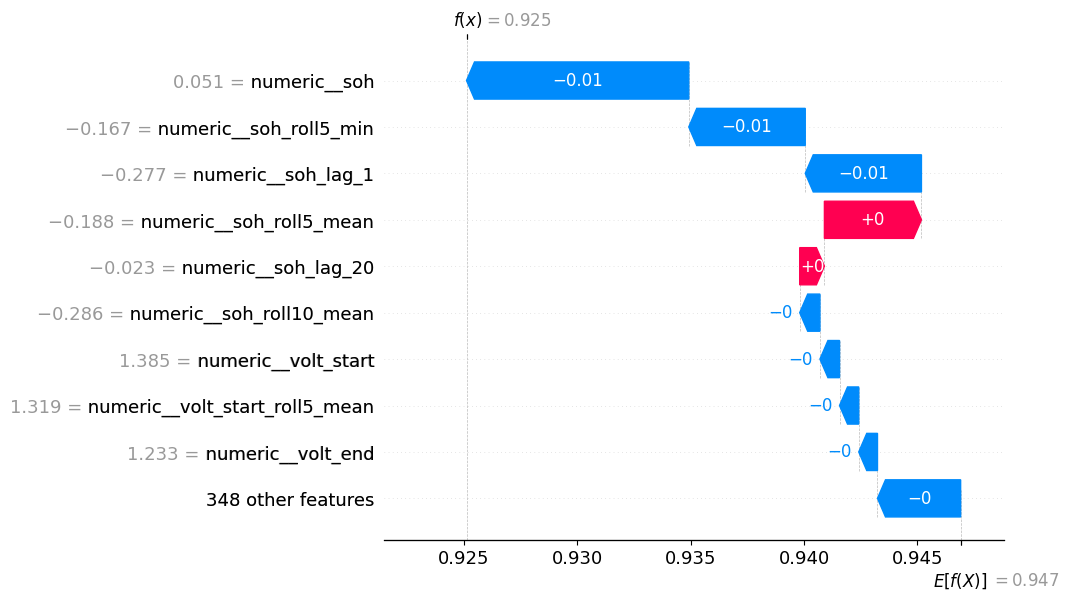

,feature,shap_value,absolute_impact
9,numeric__soh,-0.009806,0.009806
159,numeric__soh_roll5_min,-0.005139,0.005139
133,numeric__soh_lag_1,-0.005126,0.005126
157,numeric__soh_roll5_mean,0.004281,0.004281
137,numeric__soh_lag_20,0.001089,0.001089
...,...,...,...
334,categorical__car_identifier_HQ21,0.000000,0.000000
352,categorical__battery_type_LFP,0.000000,0.000000
353,categorical__battery_type_NMC,0.000000,0.000000
354,categorical__battery_type_Unknown,0.000000,0.000000


In [ ]:
explain_soh_with_shap("LFP01", 149)

In [ ]:

latest_battery_output = (
    final_combined
    .sort_values(
        ['battery_id', 'seg_num']
    )
    .groupby(
        'battery_id',
        as_index=False
    )
    .tail(1)
    .copy()
)

latest_battery_output = (
    latest_battery_output
    .sort_values(
        'acceleration_score',
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    latest_battery_output[
        [
            'battery_id',
            'battery_type',
            'charge_type',
            'seg_num',
            'current_soh',
            'predicted_soh_10',
            'predicted_soh_drop_10',
            'recent_degradation_rate',
            'baseline_degradation_rate',
            'degradation_acceleration',
            'persistence_3',
            'acceleration_score',
            'acceleration_status',
            'accelerated_regime'
        ]
    ]
)

,battery_id,battery_type,charge_type,seg_num,current_soh,predicted_soh_10,predicted_soh_drop_10,recent_degradation_rate,baseline_degradation_rate,degradation_acceleration,persistence_3,acceleration_score,acceleration_status,accelerated_regime
0,NMC01,NMC,slow,544,0.863493,0.878234,-0.014741,0.000132,-0.000807,9.389692e-04,0.333333,13.232304,LOW,False
1,NMC01_Car01,NMC,fast,561,0.834131,0.828485,0.005646,-0.000099,-0.000240,1.411413e-04,0.666667,3.978032,LOW,False
2,Lab,Unknown,fast,340,0.981852,0.981360,0.000493,-0.000009,-0.000009,-3.049488e-17,0.000000,0.000000,LOW,False
3,LFP01,LFP,fast,902,0.898914,0.896922,0.001992,-0.000017,0.000038,-5.487449e-05,0.000000,0.000000,LOW,False
4,NMC01_Car02,NMC,fast,725,0.824522,0.821008,0.003515,-0.000255,0.000221,-4.758069e-04,0.000000,0.000000,LOW,False
5,NMC02,NMC,fast,523,0.955795,0.930914,0.024880,-0.000670,-0.000349,-3.200927e-04,0.666667,0.000000,LOW,False


In [ ]:

def explain_battery_prediction(battery_id, cycle):
    """
    Test one battery/cycle from the independent test set
    and explain both outputs of the proposed framework.
    """
    result = final_combined[
        (final_combined['battery_id'] == battery_id) &
        (final_combined['seg_num'] == cycle)
    ].copy()

    if result.empty:
        print(f"No record found for battery '{battery_id}' at cycle {cycle}.")
        print("\nAvailable examples:")
        print(
            final_combined[
                ['battery_id', 'seg_num']
            ].head(20).to_string(index=False)
        )
        return None

    row = result.iloc[0]
    current_soh = row['current_soh']
    predicted_soh = row['predicted_soh_10']
    predicted_drop = row['predicted_soh_drop_10']

    recent_rate = row['recent_degradation_rate']
    baseline_rate = row['baseline_degradation_rate']
    acceleration = row['degradation_acceleration']
    persistence = row['persistence_3']
    acceleration_score = row['acceleration_score']
    acceleration_status = row['acceleration_status']
    accelerated_regime = row['accelerated_regime']

    print("=" * 75)
    print("EV BATTERY HEALTH PREDICTION")
    print("=" * 75)

    print(f"Battery ID       : {battery_id}")
    print(f"Current cycle    : {cycle}")
    print()

    # ========================================================
    # OUTPUT 1 — FUTURE SOH
    # ========================================================
    print("-" * 75)
    print("OUTPUT 1 — 10-CYCLE-AHEAD SOH FORECAST")
    print("-" * 75)

    print(f"Current SOH              : {current_soh:.6f}")
    print(f"Predicted SOH (+10)      : {predicted_soh:.6f}")
    print(f"Predicted SOH change     : {predicted_drop:.6f}")

    if predicted_drop > 0:
        print(
            f"\nInterpretation: The model predicts an SOH decrease "
            f"of approximately {predicted_drop:.4f} over the next 10 cycles."
        )
    elif predicted_drop < 0:
        print(
            f"\nInterpretation: The model predicts an SOH increase "
            f"of approximately {abs(predicted_drop):.4f} over the next 10 cycles."
        )
        print(
            "Note: A small predicted increase can occur because SOH "
            "measurements are noisy; it does not imply physical battery recovery."
        )
    else:
        print(
            "\nInterpretation: The model predicts approximately no SOH change "
            "over the next 10 cycles."
        )

    # ========================================================
    # OUTPUT 2 — DEGRADATION ACCELERATION
    # ========================================================
    print("\n" + "-" * 75)
    print("OUTPUT 2 — DEGRADATION ACCELERATION ANALYSIS")
    print("-" * 75)

    # Check whether enough history exists
    if pd.isna(recent_rate) or pd.isna(baseline_rate):

        print("Acceleration analysis: NOT AVAILABLE")
        print(
            "\nReason: This cycle does not have enough historical observations "
            "to calculate both the recent and baseline degradation rates."
        )

        print(
            "\nThe SOH forecast is still available because Output 1 "
            "does not require this trajectory calculation."
        )

        return row

    print(f"Recent degradation rate  : {recent_rate:.8f}")
    print(f"Baseline degradation rate: {baseline_rate:.8f}")
    print(f"Degradation acceleration : {acceleration:.8f}")
    print(f"Persistence (3 obs.)     : {persistence:.2f}")
    print(f"Acceleration score       : {acceleration_score:.2f}/100")
    print(f"Acceleration status      : {acceleration_status}")

    # --------------------------------------------------------
    # Explain degradation acceleration
    # --------------------------------------------------------
    print("\nInterpretation:")

    if acceleration > 0:
        print(
            f"- Recent degradation ({recent_rate:.8f}) is faster than "
            f"the baseline degradation ({baseline_rate:.8f})."
        )
        print(
            f"- Therefore degradation acceleration is positive "
            f"({acceleration:.8f})."
        )
    elif acceleration < 0:
        print(
            f"- Recent degradation ({recent_rate:.8f}) is slower than "
            f"the baseline degradation ({baseline_rate:.8f})."
        )
        print(
            f"- Therefore degradation is NOT currently accelerating."
        )
    else:
        print(
            "- Recent degradation is approximately equal to the baseline."
        )

    # --------------------------------------------------------
    # Explain persistence
    # --------------------------------------------------------
    if persistence >= 2/3:
        print(
            f"- Acceleration persists across at least 2 of the last "
            f"3 observations (persistence = {persistence:.2f})."
        )
    else:
        print(
            f"- Acceleration is not sufficiently persistent "
            f"(persistence = {persistence:.2f})."
        )

    # --------------------------------------------------------
    # Explain final status
    # --------------------------------------------------------
    print(
        f"\nFINAL ACCELERATION ASSESSMENT: {acceleration_status}"
    )

    if acceleration_status == "LOW":
        print(
            "The battery does not currently show strong and persistent "
            "evidence of accelerated degradation."
        )

    elif acceleration_status == "MEDIUM":
        print(
            "The battery shows a meaningful increase in its degradation "
            "rate and should be monitored."
        )

    elif acceleration_status == "HIGH":
        print(
            "The battery is showing strong and persistent degradation "
            "acceleration and deserves attention."
        )

    elif acceleration_status == "CRITICAL":
        print(
            "The battery is showing very strong and persistent degradation "
            "acceleration and represents a significant early-warning case."
        )

    # ========================================================
    # COMBINED CONCLUSION
    # ========================================================
    print("\n" + "=" * 75)
    print("COMBINED SYSTEM CONCLUSION")
    print("=" * 75)

    print(
        f"The battery currently has SOH = {current_soh:.4f}. "
        f"The ML model forecasts SOH = {predicted_soh:.4f} "
        f"10 cycles ahead."
    )

    if acceleration_status == "LOW":
        print(
            "At the same time, the trajectory analysis does not indicate "
            "strong current degradation acceleration."
        )
    else:
        print(
            f"Independently, the trajectory analysis detects "
            f"{acceleration_status.lower()} degradation acceleration "
            f"(score = {acceleration_score:.2f}/100)."
        )
    return row

In [ ]:
explain_battery_prediction("LFP01", 149)

EV BATTERY HEALTH PREDICTION
Battery ID       : LFP01
Current cycle    : 149

---------------------------------------------------------------------------
OUTPUT 1 — 10-CYCLE-AHEAD SOH FORECAST
---------------------------------------------------------------------------
Current SOH              : 0.950985
Predicted SOH (+10)      : 0.925108
Predicted SOH change     : 0.025877

Interpretation: The model predicts an SOH decrease of approximately 0.0259 over the next 10 cycles.

---------------------------------------------------------------------------
OUTPUT 2 — DEGRADATION ACCELERATION ANALYSIS
---------------------------------------------------------------------------
Recent degradation rate  : -0.00009354
Baseline degradation rate: 0.00016303
Degradation acceleration : -0.00025657
Persistence (3 obs.)     : 0.00
Acceleration score       : 0.00/100
Acceleration status      : LOW

Interpretation:
- Recent degradation (-0.00009354) is slower than the baseline degradation (0.00016303).
- T

,11
battery_id,LFP01
seg_num,149
current_soh,0.950985
predicted_soh_10,0.925108
predicted_soh_drop_10,0.025877
predicted_degradation_rate_10,0.002588
battery_type,LFP
charge_type,fast
recent_degradation_rate,-0.000094
baseline_degradation_rate,0.000163


In [ ]:
# Show independent-test cycles with CRITICAL acceleration
critical_cases = (
    final_combined[
        final_combined['acceleration_status'] == 'CRITICAL'
    ][
        [
            'battery_id',
            'seg_num',
            'current_soh',
            'predicted_soh_10',
            'predicted_soh_drop_10',
            'recent_degradation_rate',
            'baseline_degradation_rate',
            'degradation_acceleration',
            'persistence_3',
            'acceleration_score',
            'acceleration_status'
        ]
    ]
    .sort_values('acceleration_score', ascending=False)
)

display(critical_cases)

,battery_id,seg_num,current_soh,predicted_soh_10,predicted_soh_drop_10,recent_degradation_rate,baseline_degradation_rate,degradation_acceleration,persistence_3,acceleration_score,acceleration_status
17,LFP01,162,0.931847,0.950977,-0.019130,0.003349,-0.000058,0.003406,1.0,100.000000,CRITICAL
72,LFP01,533,0.905817,0.890893,0.014924,0.002292,-0.000259,0.002551,1.0,100.000000,CRITICAL
486,NMC01,356,0.797922,0.860753,-0.062831,0.004425,0.000957,0.003468,1.0,100.000000,CRITICAL
75,LFP01,545,0.883459,0.902242,-0.018783,0.002609,0.000011,0.002597,1.0,100.000000,CRITICAL
76,LFP01,548,0.953962,0.908939,0.045022,0.002963,0.000151,0.002813,1.0,100.000000,CRITICAL
114,LFP01,736,0.927456,0.915456,0.012000,0.002835,0.000341,0.002495,1.0,100.000000,CRITICAL
567,NMC01_Car01,85,0.869419,0.878461,-0.009042,0.002636,0.000039,0.002596,1.0,100.000000,CRITICAL
568,NMC01_Car01,86,0.867133,0.875477,-0.008344,0.002835,0.000095,0.002740,1.0,100.000000,CRITICAL
532,NMC01,507,0.851277,0.871026,-0.019749,0.003335,0.000194,0.003141,1.0,100.000000,CRITICAL
491,NMC01,390,0.778091,0.854007,-0.075916,0.002823,-0.000113,0.002936,1.0,100.000000,CRITICAL
